In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

In [3]:
df.shape

(4340, 8)

In [4]:
df.columns.tolist()

['name',
 'year',
 'selling_price',
 'km_driven',
 'fuel',
 'seller_type',
 'transmission',
 'owner']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [6]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [7]:
df.duplicated().sum()

np.int64(763)

In [8]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [9]:
df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object


In [10]:
cat_cols=df.select_dtypes(include="object").columns

In [11]:
cat_cols

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')

In [12]:
for col in cat_cols:
    print(df[col].value_counts())
    print()

name
Maruti Swift Dzire VDI                            69
Maruti Alto 800 LXI                               59
Maruti Alto LXi                                   47
Hyundai EON Era Plus                              35
Maruti Alto LX                                    35
                                                  ..
Honda Brio 1.2 S Option MT                         1
Mahindra Bolero Power Plus Plus Non AC BSIV PS     1
Tata Indigo LS BSII                                1
Force One EX                                       1
Chevrolet Aveo 1.4 LT BSIV                         1
Name: count, Length: 1491, dtype: int64

fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

owner
First Owner             2832
Second Owner            1106


In [13]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [14]:
# Remove extra spaces and standardize categorical values

for column in cat_cols:
    df[column] = df[column].str.strip().str.title()

In [15]:
for column in cat_cols:
    print(f"\n{column}:")
    print(df[column].unique())


name:
['Maruti 800 Ac' 'Maruti Wagon R Lxi Minor' 'Hyundai Verna 1.6 Sx' ...
 'Mahindra Verito 1.5 D6 Bsiii'
 'Toyota Innova 2.5 Vx (Diesel) 8 Seater Bs Iv'
 'Hyundai I20 Magna 1.4 Crdi']

fuel:
['Petrol' 'Diesel' 'Cng' 'Lpg' 'Electric']

seller_type:
['Individual' 'Dealer' 'Trustmark Dealer']

transmission:
['Manual' 'Automatic']

owner:
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


In [16]:
import datetime as dt
current_year = dt.datetime.now().year
df['car_age'] = current_year - df['year']

In [17]:
df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
car_age,int64


In [18]:
df[['year', 'car_age']].head()

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12


In [19]:
# Extracting brand from car name
df['brand'] = df['name'].str.split().str[0]
df[['name', 'brand']].head()

,name,brand
0,Maruti 800 Ac,Maruti
1,Maruti Wagon R Lxi Minor,Maruti
2,Hyundai Verna 1.6 Sx,Hyundai
3,Datsun Redigo T Option,Datsun
4,Honda Amaze Vx I-Dtec,Honda


In [20]:
df['brand'].value_counts()

,count
brand,
Maruti,1280
Hyundai,821
Mahindra,365
Tata,361
Honda,252
Ford,238
Toyota,206
Chevrolet,188
Renault,146


In [21]:
df['brand'].nunique() #number of unique brands

29

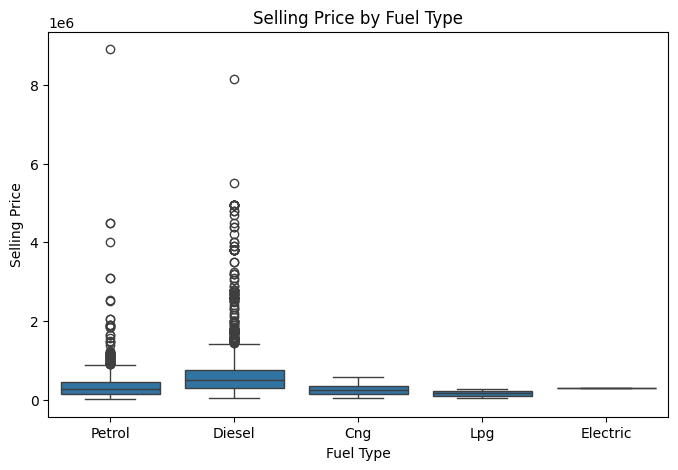

In [22]:
#Selling price by Fuel Type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x='fuel', y='selling_price')
plt.title('Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')

plt.show()

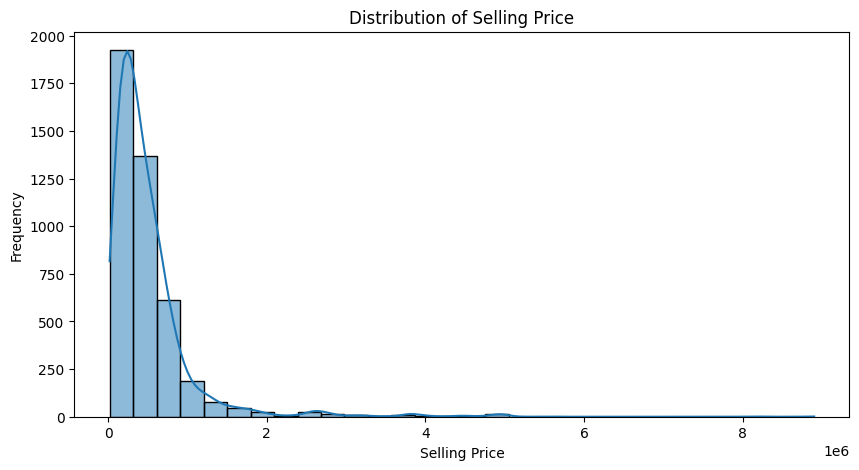

In [23]:
#Distribution of Selling Price
plt.figure(figsize=(10, 5))
sns.histplot(data=df,x='selling_price',bins=30,kde=True)
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price')
plt.ylabel('Frequency')

plt.show()

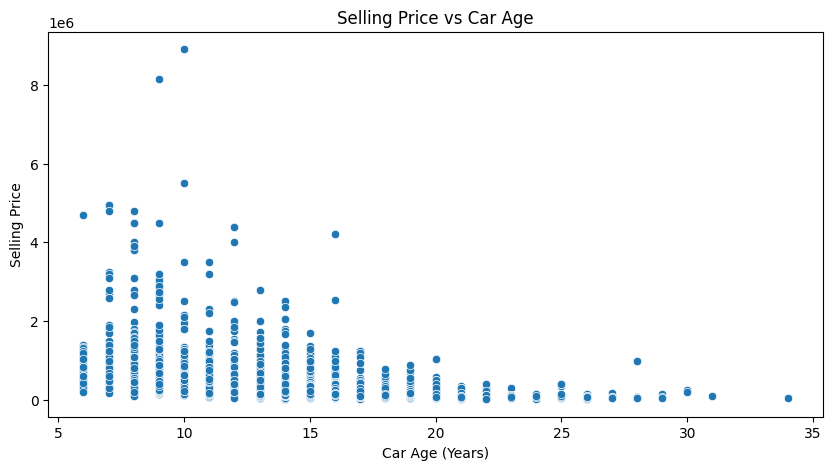

In [24]:
#selling price vs car age
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='car_age',
    y='selling_price'
)

plt.title('Selling Price vs Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price')

plt.show()

In [25]:
# Select numerical columns for correlation analysis

numerical_columns = [
    'year',
    'selling_price',
    'km_driven',
    'car_age'
]

corr_matrix = df[numerical_columns].corr()

corr_matrix

,year,selling_price,km_driven,car_age
year,1.000000,0.413922,-0.419688,-1.000000
selling_price,0.413922,1.000000,-0.192289,-0.413922
km_driven,-0.419688,-0.192289,1.000000,0.419688
car_age,-1.000000,-0.413922,0.419688,1.000000


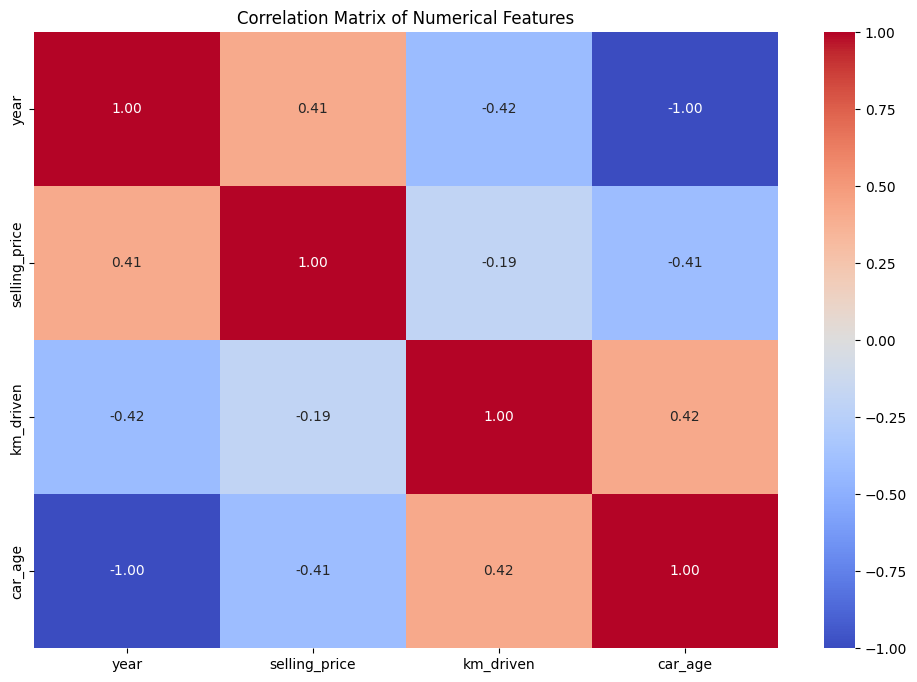

In [26]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [27]:
# Define features and target

X = df[
    [
        'km_driven',
        'fuel',
        'seller_type',
        'transmission',
        'owner',
        'car_age',
        'brand'
    ]
]

y = df['selling_price']

In [28]:
from sklearn.model_selection import train_test_split
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3472, 7)
Testing data: (868, 7)


In [29]:
# Identify categorical columns
categorical_columns = ['fuel', 'seller_type','transmission','owner','brand']
print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['fuel', 'seller_type', 'transmission', 'owner', 'brand']


In [30]:
numerical_columns = [
    'km_driven',
    'car_age'
]

In [31]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [32]:
# Create OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [33]:
# Apply One-Hot Encoding to categorical columns
# Keep numerical columns unchanged

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', encoder, categorical_columns)
    ],
    remainder='passthrough'
)

In [34]:
# Fit the encoder on training data and transform it

X_train_encoded = preprocessor.fit_transform(X_train)

# Transform the test data

X_test_encoded = preprocessor.transform(X_test)

In [35]:
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (3472, 45)
Encoded testing shape: (868, 45)


In [36]:
# Get feature names after One-Hot Encoding

feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 45
['categorical__fuel_Cng' 'categorical__fuel_Diesel'
 'categorical__fuel_Electric' 'categorical__fuel_Lpg'
 'categorical__fuel_Petrol' 'categorical__seller_type_Dealer'
 'categorical__seller_type_Individual'
 'categorical__seller_type_Trustmark Dealer'
 'categorical__transmission_Automatic' 'categorical__transmission_Manual'
 'categorical__owner_First Owner'
 'categorical__owner_Fourth & Above Owner'
 'categorical__owner_Second Owner' 'categorical__owner_Test Drive Car'
 'categorical__owner_Third Owner' 'categorical__brand_Ambassador'
 'categorical__brand_Audi' 'categorical__brand_Bmw'
 'categorical__brand_Chevrolet' 'categorical__brand_Datsun'
 'categorical__brand_Fiat' 'categorical__brand_Force'
 'categorical__brand_Ford' 'categorical__brand_Honda'
 'categorical__brand_Hyundai' 'categorical__brand_Isuzu'
 'categorical__brand_Jaguar' 'categorical__brand_Jeep'
 'categorical__brand_Kia' 'categorical__brand_Land'
 'categorical__brand_Mahindra' 'categorical__brand_Ma

In [37]:
# model 1

# Import Linear Regression

from sklearn.linear_model import LinearRegression

In [38]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train_encoded, y_train)

LinearRegression()

In [39]:
# Make predictions on the test data

y_pred_linear = linear_model.predict(X_test_encoded)

print(y_pred_linear[:10])

[258083.04751168 482446.50061745 108678.7015516  490117.46474965
 980180.27151489 259719.34992682 510911.46755845 292348.54271179
 577755.67229066 367168.95084172]


In [40]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [41]:
# Calculate Mean Absolute Error

mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

print("Linear Regression MAE:", mae_linear)

Linear Regression MAE: 185155.60159585017


In [42]:
# Calculate Root Mean Squared Error

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

print("Linear Regression RMSE:", rmse_linear)

Linear Regression RMSE: 378943.9596916428


In [43]:
# Calculate R-squared score

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression R²:", r2_linear)

Linear Regression R²: 0.5294478816099606


In [44]:
# Model 2

# Import Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

In [45]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [46]:
# Train Random Forest

rf_model.fit(X_train_encoded, y_train)

RandomForestRegressor(random_state=42)

In [47]:
# Make predictions on the test data

y_pred_rf = rf_model.predict(X_test_encoded)

print(y_pred_rf[:10])

[ 152020.83333333  360770.          128043.33333333  425249.98
 1131949.51        223820.25333333  541339.97        113698.66666667
  441919.76        337800.        ]


In [48]:
# Evaluate MAE
# Calculate MAE

mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

# Calculate RMSE

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

# Calculate R²

r2_rf = r2_score(
    y_test,
    y_pred_rf
)

print("Random Forest MAE:", mae_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest R²:", r2_rf)

Random Forest MAE: 114562.64217171671
Random Forest RMSE: 271374.37480158644
Random Forest R²: 0.7586788273398702


In [49]:
# Compare model performance

results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_rf
    ],
    'RMSE': [
        rmse_linear,
        rmse_rf
    ],
    'R²': [
        r2_linear,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R²
0,Linear Regression,185155.601596,378943.959692,0.529448
1,Random Forest,114562.642172,271374.374802,0.758679


In [50]:
# Identify the best-performing model based on R²

best_model = results.loc[
    results['R²'].idxmax()
]

print("Best Model:", best_model['Model'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])
print("R²:", best_model['R²'])

Best Model: Random Forest
MAE: 114562.64217171671
RMSE: 271374.37480158644
R²: 0.7586788273398702


In [51]:
rf_model.feature_importances_

array([8.04504394e-05, 9.82226432e-02, 2.15970066e-05, 1.39658334e-05,
       1.90043517e-02, 2.12007412e-02, 1.12248711e-02, 2.91106026e-03,
       1.55776281e-01, 1.37987816e-01, 4.45800421e-03, 2.03844682e-04,
       4.29780498e-03, 3.22680328e-04, 1.32398706e-03, 2.91739573e-05,
       1.86152303e-02, 3.91732428e-02, 1.86868768e-03, 4.17486459e-04,
       3.11115619e-04, 3.95702542e-06, 7.29720381e-03, 3.53494767e-03,
       4.32783100e-03, 3.57907419e-04, 7.96429917e-03, 1.58282022e-03,
       6.64502581e-04, 2.12401541e-02, 4.53122826e-03, 1.08719791e-02,
       5.22688389e-02, 2.08253038e-03, 1.57250484e-03, 7.08967455e-04,
       8.51381843e-07, 1.20310322e-03, 2.12604930e-03, 3.87448543e-03,
       2.67765248e-02, 2.74874353e-03, 7.32481892e-03, 1.34670067e-01,
       1.84800649e-01])

In [52]:
# Get feature importance from Random Forest

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
44,remainder__car_age,0.184801
8,categorical__transmission_Automatic,0.155776
9,categorical__transmission_Manual,0.137988
43,remainder__km_driven,0.134670
1,categorical__fuel_Diesel,0.098223
32,categorical__brand_Mercedes-Benz,0.052269
17,categorical__brand_Bmw,0.039173
40,categorical__brand_Toyota,0.026777
29,categorical__brand_Land,0.021240
5,categorical__seller_type_Dealer,0.021201


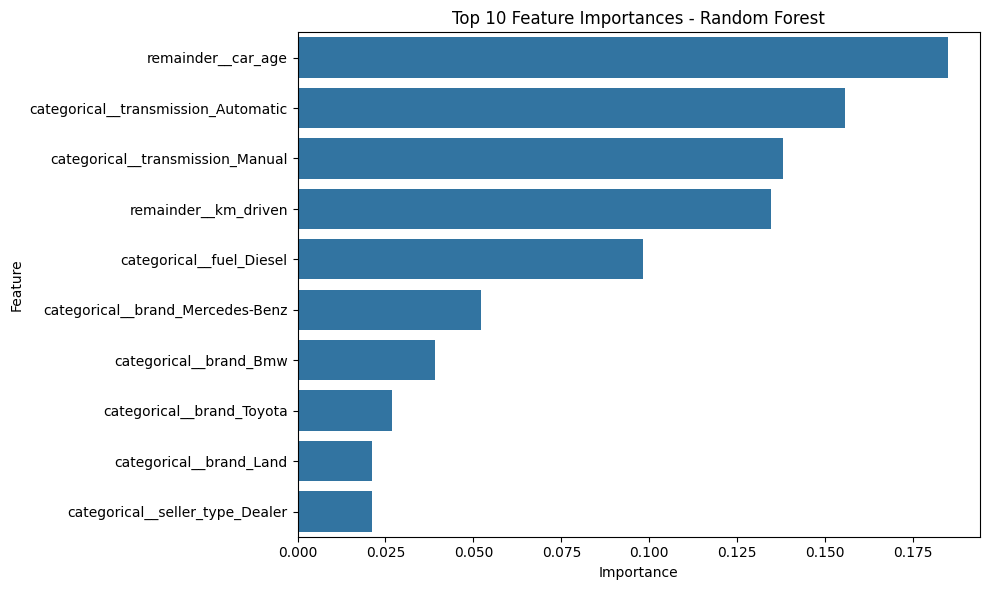

In [53]:
# Plot the top 10 important features

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### **Conclusion**

- **Random Forest outperformed Linear Regression** across all three evaluation metrics, demonstrating better predictive performance.
- Random Forest achieved an **R² score of 0.7587**, explaining approximately **75.87% of the variance** in the target variable, compared with 52.94% for Linear Regression.
- It also achieved lower prediction errors, with an **MAE of 114,562.64** and an **RMSE of 271,374.37**, compared with Linear Regression's MAE of 185,155.60 and RMSE of 378,943.96.
- **Overall, Random Forest is the better-performing model** for this dataset because it captures the underlying patterns more effectively and produces more accurate predictions. Further hyperparameter tuning and feature engineering may improve its performance.